# Issue #206 — fixed-N7 constrained ticket policy

This thin notebook verifies the immutable package, renders the frozen chronological decision, and inspects the label-blind Stage-3 handoff. Core generation, modeling, settlement, and plotting live in `src/ticket_policy/fixed_n7.py`.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd

ROOT = Path.cwd().parents[2]
sys.path.insert(0, str(ROOT / 'src'))
from ticket_policy.fixed_n7 import verify

PACKAGE = ROOT / 'results' / 'issue-206'
verification = verify(PACKAGE)
decision = json.loads((PACKAGE / 'decision.json').read_text(encoding='utf-8'))
surface = pd.read_csv(PACKAGE / 'policy_surface.csv')
calibration = pd.read_csv(PACKAGE / 'ticket_calibration.csv')
requests = pd.read_parquet(PACKAGE / 'ticket_requests.parquet')
issue_gate = pd.read_csv(PACKAGE / 'issue_gate.csv')
verification, decision

({'status': 'PASS',
  'files': 16,
  'manifest_sha256': '7f4d73b5b7e7c267c050f4da794ac85d9b502080b2ee7fb0da983a8e82b5724d',
  'request_rows': 0,
  'issues': 75,
  'excluded_input_matches': 651},
 {'accepted_baseline_comparability': 'NO_COMPARABLE_ACCEPTED_TICKET_POLICY_ON_MATCHED_STAGE3_SUPPORT',
  'accepted_baseline_identity': '#205_MARKET_INDEPENDENCE_PROBABILITY_SCORER_ONLY',
  'accepted_ticket_baseline_bound': False,
  'advance_learned_policy': False,
  'challenger_k': 8,
  'challenger_policy': 'LEARNED_MLP',
  'disposition': 'LEARNED_POLICY_REJECTED_BASELINE_UNRESOLVED',
  'evaluation_split': 'CV_2023',
  'fallback_mixed_k': 0,
  'fallback_mixed_policy': 'NO_BET',
  'fallback_reason': 'ACCEPTED_TICKET_BASELINE_UNRESOLVED_NO_BET',
  'issue_specific_gate': 'issue_gate.csv',
  'label_embargo': 'No LOCKED_TEST (2025/2026) outcome or official-final-SP label enters training, selection, or evaluation',
  'locked_ood_issues': 0,
  'matched_turnover': 928.0,
  'ood_features': ['log_joint_p

In [2]:
evaluation = surface.loc[(surface['split'] == 'CV_2023') & surface['stake_budget_matched'], [
    'policy', 'k', 'turnover', 'expected_pre_tax_net', 'realized_pre_tax_net',
    'coverage', 'match_overlap', 'repeat_share',
    'matched_lift_realized_pre_tax_net'
]].sort_values('realized_pre_tax_net', ascending=False)
evaluation, calibration.head(10)

(                       policy  k  turnover  expected_pre_tax_net  \
 39                 MARKET_WOR  8     880.0             76.204753   
 30  EXPERIMENTAL_MLP_ABLATION  8     880.0              4.423823   
 33                LEARNED_MLP  8     880.0              0.359653   
 36          LOGISTIC_BASELINE  8     880.0              2.818778   
 42                  MARKET_WR  8     880.0             78.369429   
 45             OVERLAP_CAPPED  8     880.0            131.827050   
 48          OVERLAP_PENALIZED  8     880.0            131.827037   
 51            TEMPERATURE_050  8     880.0             55.047150   
 54            TEMPERATURE_100  8     880.0             78.076211   
 57             TOP_K_EXPECTED  8     880.0            131.827050   
 
     realized_pre_tax_net  coverage  match_overlap  repeat_share  \
 39             -0.857525  0.018182       0.178571      0.000000   
 30             -1.000000  0.000000       0.052597      0.000000   
 33             -1.000000  0.000000

In [3]:
handoff_receipt = {
    'issues': int(requests['issue'].nunique()),
    'requested_tickets': int(len(requests)),
    'requested_stake_yuan': int(requests['requested_stake'].sum()),
    'all_n_exactly_7': bool(requests['n'].eq(7).all()),
    'labels_used': bool(requests['labels_used'].any()),
    'fallback_share': float(requests['fallback_applied'].mean()),
    'ood_issues': int(issue_gate['ood_flag'].sum()),
    'no_bet_issues': int(issue_gate['fallback_mixed_path'].eq('NO_BET').sum()),
    'repeat_ticket_rows': int(requests.duplicated(['issue', 'ticket_identity']).sum()),
}
handoff_receipt, issue_gate.head(8)[['issue', 'ood_score', 'ood_threshold', 'learned_only_path', 'pure_control_path', 'fallback_mixed_path', 'fallback_reason']]

({'issues': 0,
  'requested_tickets': 0,
  'requested_stake_yuan': 0,
  'all_n_exactly_7': True,
  'labels_used': False,
  'fallback_share': nan,
  'ood_issues': 0,
  'no_bet_issues': 75,
  'repeat_ticket_rows': 0},
    issue  ood_score  ood_threshold learned_only_path pure_control_path  \
 0  25043   0.732732       7.549834       LEARNED_MLP         MARKET_WR   
 1  25044   1.161762       7.549834       LEARNED_MLP         MARKET_WR   
 2  25051   1.659527       7.549834       LEARNED_MLP         MARKET_WR   
 3  25052   1.196090       7.549834       LEARNED_MLP         MARKET_WR   
 4  25053   2.108616       7.549834       LEARNED_MLP         MARKET_WR   
 5  25054   1.506678       7.549834       LEARNED_MLP         MARKET_WR   
 6  25055   7.549834       7.549834       LEARNED_MLP         MARKET_WR   
 7  25061   1.486917       7.549834       LEARNED_MLP         MARKET_WR   
 
   fallback_mixed_path                             fallback_reason  
 0              NO_BET  ACCEPTED_TICKE

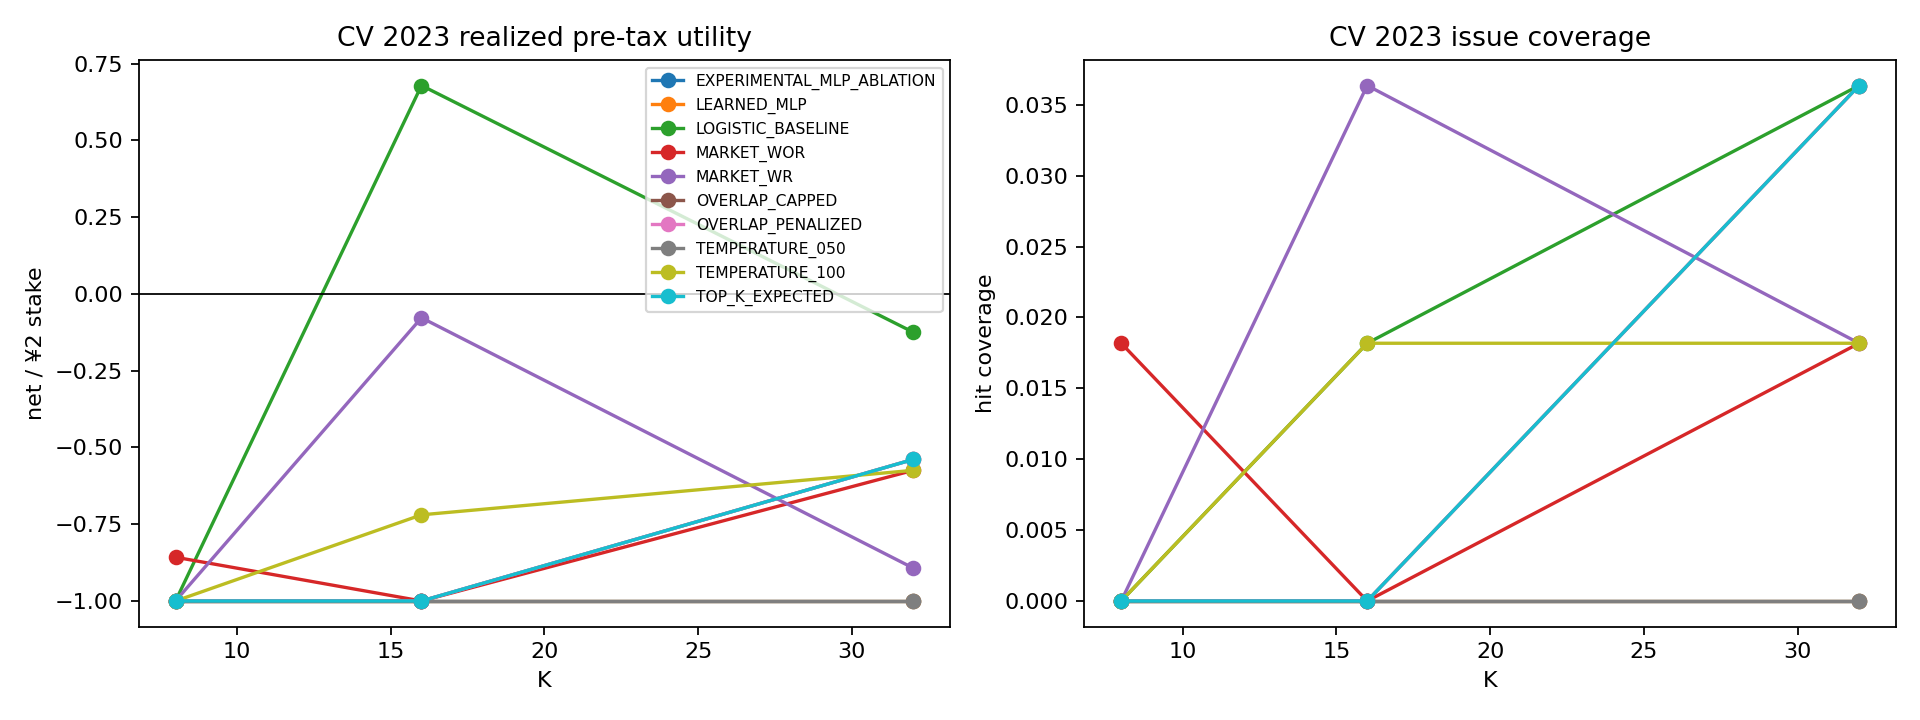

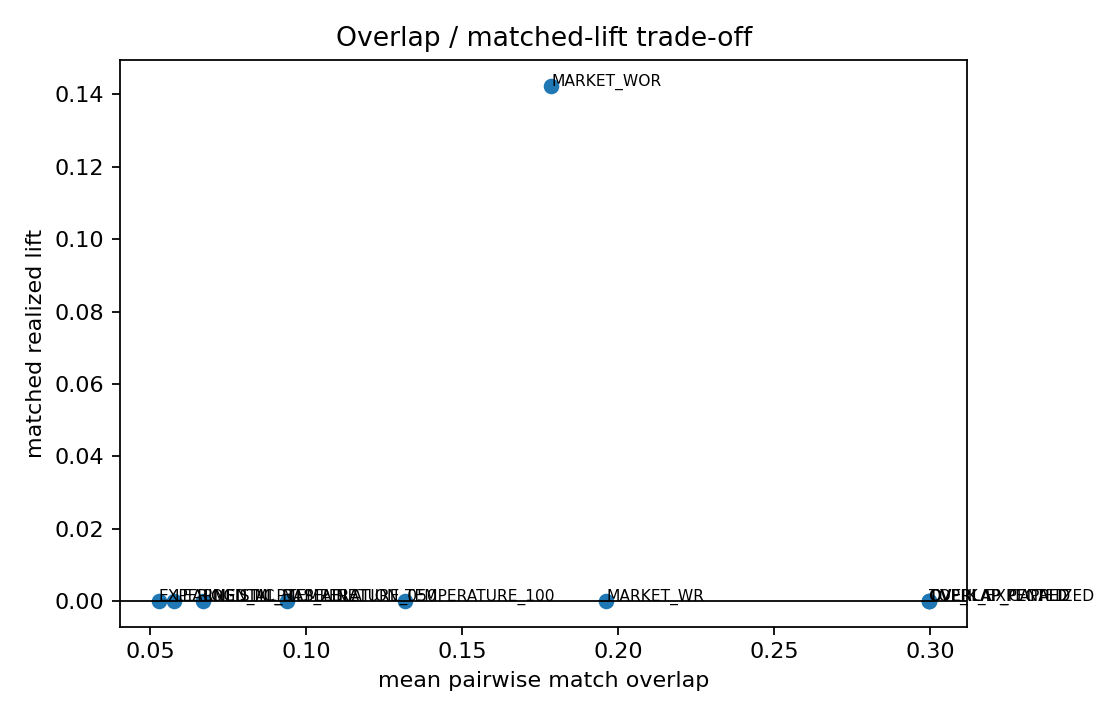

In [4]:
from IPython.display import Image, display
display(Image(filename=str(PACKAGE / 'policy_surface.png')))
display(Image(filename=str(PACKAGE / 'overlap_lift.png')))